In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.dummy import DummyRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

import warnings
warnings.filterwarnings('ignore')
sns.set_theme(style="whitegrid")

In [ ]:
diabetes = load_diabetes(as_frame=True)
df = diabetes.frame.copy()

# Rename the target column to make its meaning clear
df = df.rename(columns={"target": "Disease_Progression"})
df.head()

,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,Disease_Progression
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646,151.0
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204,75.0
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930,141.0
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362,206.0
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641,135.0


In [ ]:
print("Dataset shape:", df.shape)
print("\\nColumn names:")
print(df.columns.tolist())
print("\\nDataset information:")
df.info()

Dataset shape: (442, 11)
\nColumn names:
['age', 'sex', 'bmi', 'bp', 's1', 's2', 's3', 's4', 's5', 's6', 'Disease_Progression']
\nDataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 442 entries, 0 to 441
Data columns (total 11 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   age                  442 non-null    float64
 1   sex                  442 non-null    float64
 2   bmi                  442 non-null    float64
 3   bp                   442 non-null    float64
 4   s1                   442 non-null    float64
 5   s2                   442 non-null    float64
 6   s3                   442 non-null    float64
 7   s4                   442 non-null    float64
 8   s5                   442 non-null    float64
 9   s6                   442 non-null    float64
 10  Disease_Progression  442 non-null    float64
dtypes: float64(11)
memory usage: 38.1 KB


In [ ]:
print("Missing values in each column:")
print(df.isnull().sum())

print("\\nNumber of duplicate rows:", df.duplicated().sum())

print("\\nStatistical summary:")
df.describe().T

Missing values in each column:
age                    0
sex                    0
bmi                    0
bp                     0
s1                     0
s2                     0
s3                     0
s4                     0
s5                     0
s6                     0
Disease_Progression    0
dtype: int64
\nNumber of duplicate rows: 0
\nStatistical summary:


,count,mean,std,min,25%,50%,75%,max
age,442.0,-2.511817e-19,0.047619,-0.107226,-0.037299,0.005383,0.038076,0.110727
sex,442.0,1.230790e-17,0.047619,-0.044642,-0.044642,-0.044642,0.050680,0.050680
bmi,442.0,-2.245564e-16,0.047619,-0.090275,-0.034229,-0.007284,0.031248,0.170555
bp,442.0,-4.797570e-17,0.047619,-0.112399,-0.036656,-0.005670,0.035644,0.132044
s1,442.0,-1.381499e-17,0.047619,-0.126781,-0.034248,-0.004321,0.028358,0.153914
s2,442.0,3.918434e-17,0.047619,-0.115613,-0.030358,-0.003819,0.029844,0.198788
s3,442.0,-5.777179e-18,0.047619,-0.102307,-0.035117,-0.006584,0.029312,0.181179
s4,442.0,-9.042540e-18,0.047619,-0.076395,-0.039493,-0.002592,0.034309,0.185234
s5,442.0,9.293722e-17,0.047619,-0.126097,-0.033246,-0.001947,0.032432,0.133597
s6,442.0,1.130318e-17,0.047619,-0.137767,-0.033179,-0.001078,0.027917,0.135612


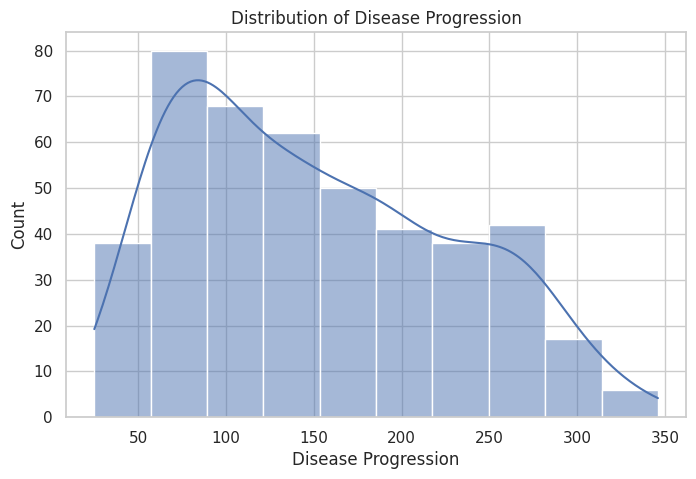

In [ ]:
# Distribution of the target variable
plt.figure(figsize=(8, 5))
sns.histplot(df["Disease_Progression"], kde=True)
plt.title("Distribution of Disease Progression")
plt.xlabel("Disease Progression")
plt.show()

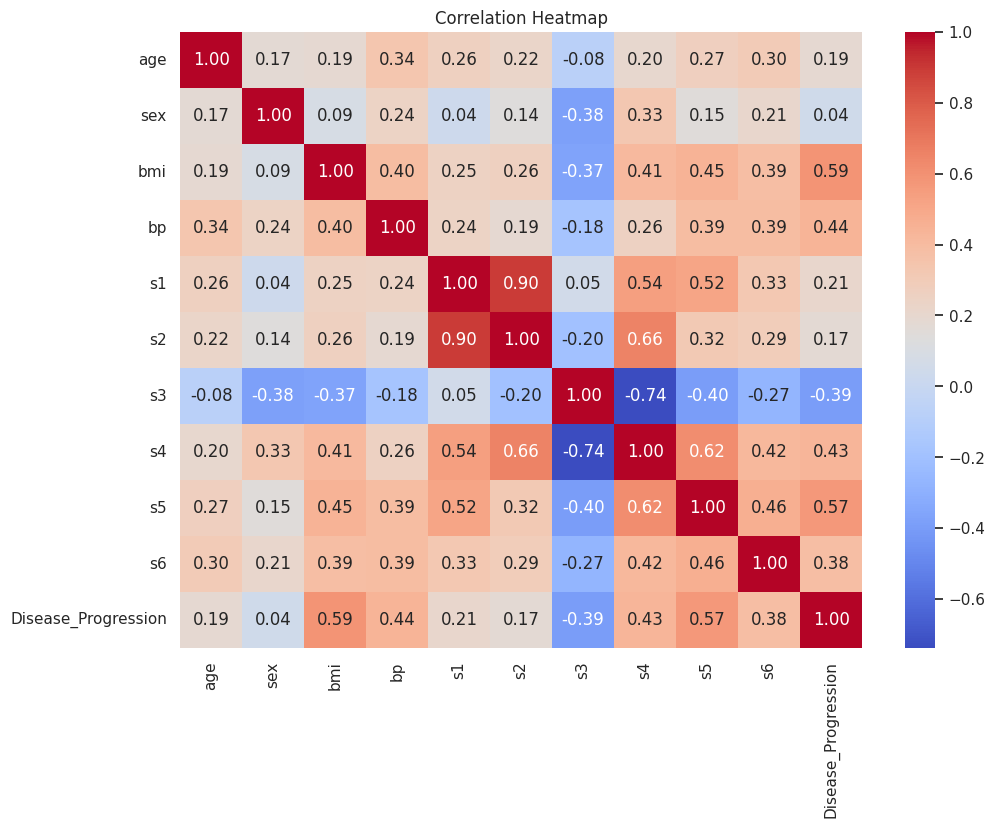

In [ ]:
# Correlation between numerical features
plt.figure(figsize=(11, 8))
sns.heatmap(df.corr(), cmap="coolwarm", annot=True, fmt=".2f")
plt.title("Correlation Heatmap")
plt.show()

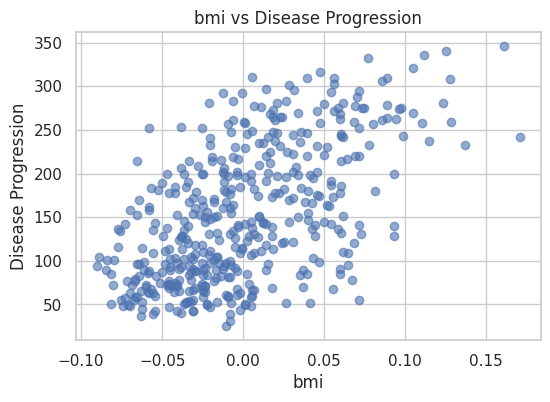

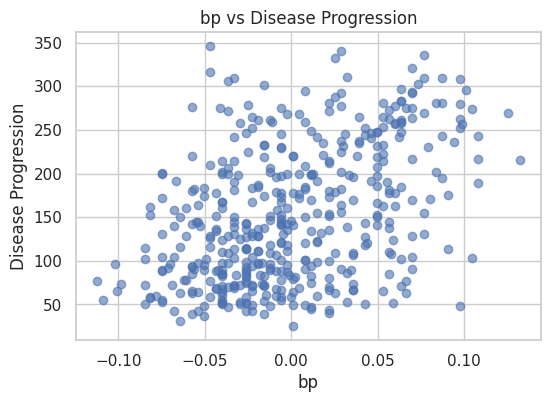

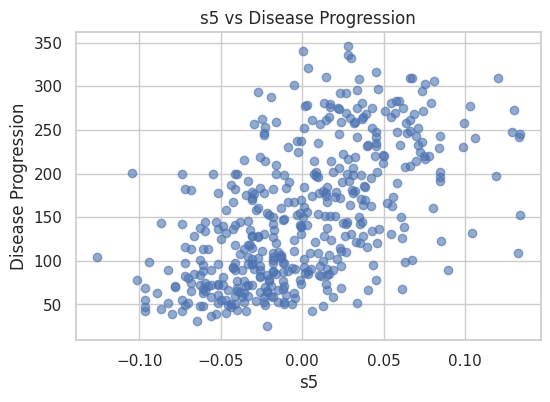

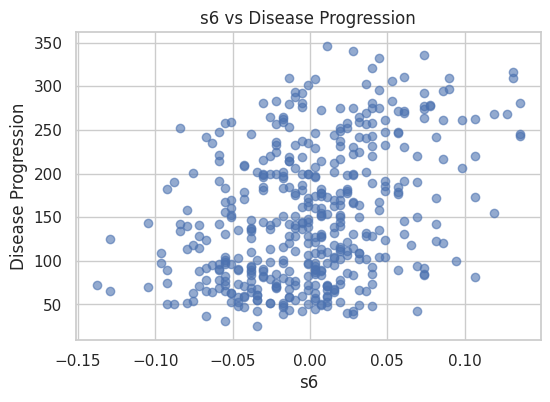

In [ ]:
# Relationship of selected features with the target
selected_features = ["bmi", "bp", "s5", "s6"]

for feature in selected_features:
    plt.figure(figsize=(6, 4))
    plt.scatter(df[feature], df["Disease_Progression"], alpha=0.6)
    plt.xlabel(feature)
    plt.ylabel("Disease Progression")
    plt.title(f"{feature} vs Disease Progression")
    plt.show()

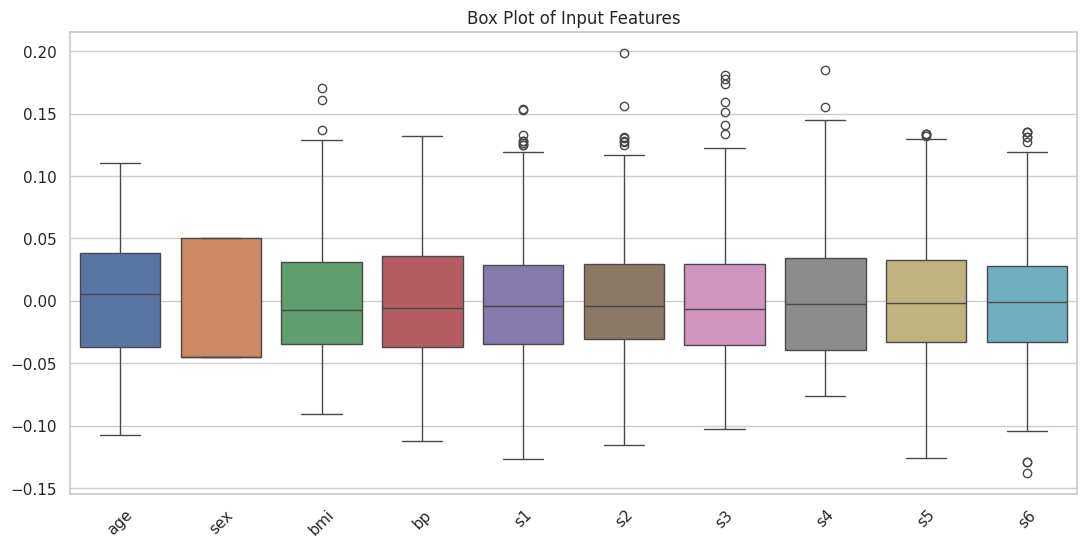

In [ ]:
plt.figure(figsize=(13, 6))
sns.boxplot(data=df.drop(columns="Disease_Progression"))
plt.title("Box Plot of Input Features")
plt.xticks(rotation=45)
plt.show()

# We inspect outliers but do not remove rows automatically.
# Tree-based models are generally less sensitive to feature scaling and extreme values.

In [ ]:
X = df.drop(columns="Disease_Progression")
y = df["Disease_Progression"]

print("Feature shape:", X.shape)
print("Target shape:", y.shape)

Feature shape: (442, 10)
Target shape: (442,)


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42
)

print("Training feature set:", X_train.shape)
print("Testing feature set:", X_test.shape)
print("Training target set:", y_train.shape)
print("Testing target set:", y_test.shape)

Training feature set: (353, 10)
Testing feature set: (89, 10)
Training target set: (353,)
Testing target set: (89,)


In [ ]:
model = RandomForestRegressor(
    n_estimators=200,
    max_depth=5,
    min_samples_split=4,
    random_state=42
)

model.fit(X_train, y_train)
print("Random Forest model training completed.")

Random Forest model training completed.


In [ ]:
y_pred = model.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("Mean Absolute Error (MAE):", round(mae, 2))
print("Mean Squared Error (MSE):", round(mse, 2))
print("Root Mean Squared Error (RMSE):", round(rmse, 2))
print("R2 Score:", round(r2, 3))

Mean Absolute Error (MAE): 43.39
Mean Squared Error (MSE): 2871.17
Root Mean Squared Error (RMSE): 53.58
R2 Score: 0.458


In [ ]:
baseline = DummyRegressor(strategy="mean")
baseline.fit(X_train, y_train)
baseline_pred = baseline.predict(X_test)

print("Baseline MAE:", round(mean_absolute_error(y_test, baseline_pred), 2))
print("Random Forest MAE:", round(mae, 2))
print("Baseline R2:", round(r2_score(y_test, baseline_pred), 3))
print("Random Forest R2:", round(r2, 3))

Baseline MAE: 64.01
Random Forest MAE: 43.39
Baseline R2: -0.012
Random Forest R2: 0.458


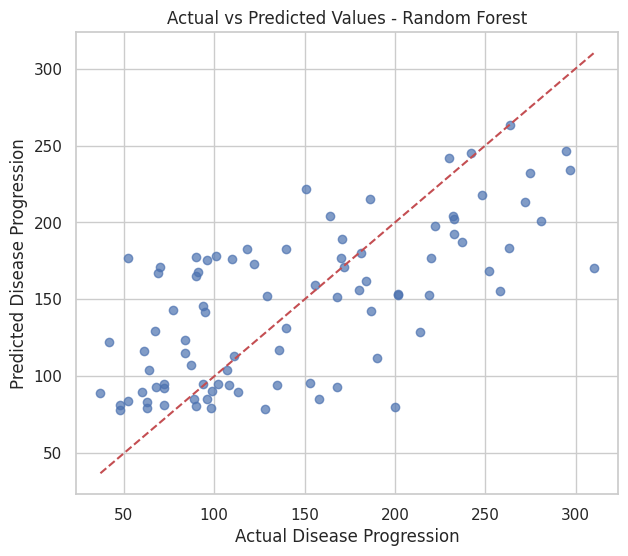

In [ ]:
plt.figure(figsize=(7, 6))
plt.scatter(y_test, y_pred, alpha=0.7)

min_val = min(y_test.min(), y_pred.min())
max_val = max(y_test.max(), y_pred.max())
plt.plot([min_val, max_val], [min_val, max_val], "r--")

plt.xlabel("Actual Disease Progression")
plt.ylabel("Predicted Disease Progression")
plt.title("Actual vs Predicted Values - Random Forest")
plt.show()

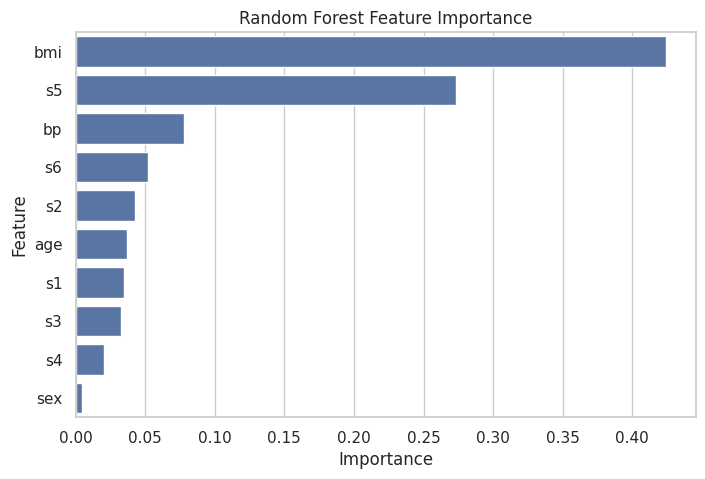

bmi    0.424322
s5     0.273115
bp     0.077873
s6     0.052337
s2     0.042682
age    0.037233
s1     0.034809
s3     0.032518
s4     0.020517
sex    0.004592
dtype: float64


In [ ]:
importance = pd.Series(
    model.feature_importances_,
    index=X.columns
).sort_values(ascending=False)

plt.figure(figsize=(8, 5))
sns.barplot(x=importance.values, y=importance.index)
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("Random Forest Feature Importance")
plt.show()

print(importance)